# Hồi quy Logistic (Logistic Regression)

Dù có chữ "Regression" trong tên, Logistic Regression thực chất là một thuật toán **Phân loại nhị phân (Binary Classification)**. Thuật toán này không dự đoán một giá trị thực, mà dự đoán xác suất $P(y=1|x)$ bằng cách đưa đầu ra của hàm tuyến tính qua hàm kích hoạt Sigmoid.

**1. Hàm giả thuyết (Hypothesis):**
$$\hat{y} = \sigma(\Phi w) = \frac{1}{1 + e^{-\Phi w}}$$
Đầu ra của hàm Sigmoid luôn bị ép về khoảng $(0, 1)$, hoàn hảo để biểu diễn xác suất.

**2. Hàm mất mát (Binary Cross-Entropy / Log Loss):**
Thay vì dùng MSE (sẽ tạo ra một bề mặt mất mát nhiều nếp gấp, không lồi khi kết hợp với Sigmoid), ta sử dụng Log Loss để đảm bảo hàm lồi, chỉ có một cực tiểu toàn cục duy nhất:
$$\mathcal{L}(w) = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]$$

**3. Tối ưu hóa (Gradient Descent):**
Nhờ sự kỳ diệu của đạo hàm, khi kết hợp Log Loss và Sigmoid, gradient triệt tiêu các thành phần phức tạp và có dạng y hệt như Hồi quy tuyến tính:
$$\nabla_w \mathcal{L} = \Phi^T \frac{(\hat{y} - y)}{N}$$
Quy tắc cập nhật: $w^{(t+1)} = w^{(t)} - \eta \nabla_w \mathcal{L}$

In [1]:
import numpy as np
from utils.losses import BinaryCrossEntropy
from utils.activations import sigmoid

class LogisticRegressionGD:
    """Phân loại nhị phân tối ưu bằng Gradient Descent."""
    def __init__(self, learning_rate=0.1, epochs=1000, fit_intercept=True):
        self.lr = learning_rate
        self.epochs = epochs
        self.fit_intercept = fit_intercept
        self.weights = None
        self.intercept = None
        self.loss_history = []
        self.bce = BinaryCrossEntropy() # Tái sử dụng engine Log Loss

    def fit(self, X: np.ndarray, y: np.ndarray):
        X, y = np.asarray(X), np.asarray(y).reshape(-1, 1)
        N = X.shape[0]
        Phi = np.hstack([np.ones((N, 1)), X]) if self.fit_intercept else X
        
        # Khởi tạo trọng số ngẫu nhiên nhỏ
        np.random.seed(42)
        w = np.random.randn(Phi.shape[1], 1) * 0.01

        for _ in range(self.epochs):
            # Forward pass: Tuyến tính -> Sigmoid
            z = Phi @ w
            y_pred = sigmoid(z)
            
            # Tính và lưu Loss
            loss = self.bce.forward(y, y_pred)
            self.loss_history.append(loss)
            
            # Backward pass: dL/dz = (y_pred - y) / N
            # Đây là kết quả rút gọn của Chain Rule: dL/dy_pred * dy_pred/dz
            grad_z = (y_pred - y) / N
            grad_w = Phi.T @ grad_z
            
            # Cập nhật trọng số
            w -= self.lr * grad_w

        if self.fit_intercept:
            self.intercept, self.weights = float(w[0, 0]), w[1:].flatten()
        else:
            self.intercept, self.weights = 0.0, w.flatten()
        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        """Trả về xác suất dự đoán P(y=1|X)"""
        z = np.asarray(X) @ self.weights + self.intercept
        return sigmoid(z)

    def predict(self, X: np.ndarray, threshold=0.5) -> np.ndarray:
        """Trả về nhãn phân loại 0 hoặc 1"""
        return (self.predict_proba(X) >= threshold).astype(int)

f:\conda-path\envs\env_researcher\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Metric               | Scratch         | Sklearn        
-------------------------------------------------------
Accuracy Score       | 0.8667          | 0.8667         
Time (ms)            | 14.82           | 12.21          


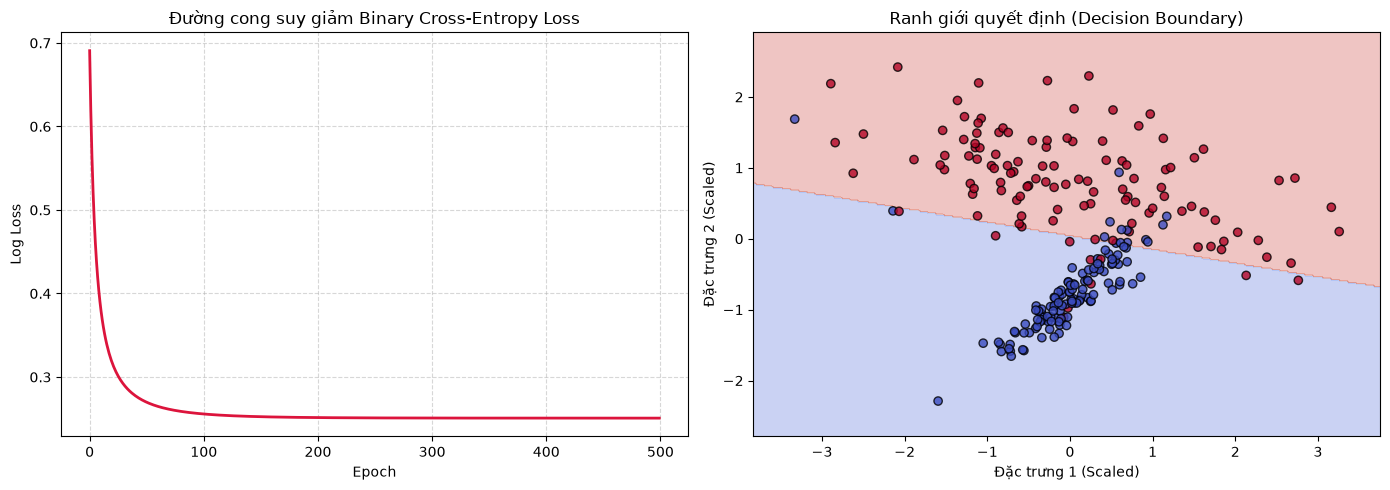

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from utils.metrics import accuracy_score
from utils.preprocessing import StandardScaler, train_test_split

# 1. Sinh dữ liệu phân loại nhị phân 2 chiều
X, y = make_classification(n_samples=300, n_features=2, n_informative=2, 
                           n_redundant=0, n_clusters_per_class=1, 
                           flip_y=0.05, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Huấn luyện model Scratch
t0 = time.time()
model_scratch = LogisticRegressionGD(learning_rate=0.5, epochs=500).fit(X_train_scaled, y_train)
t_scratch = (time.time() - t0) * 1000

# 4. Huấn luyện model Sklearn (penalty=None tương đương Hồi quy Logistic chuẩn)
t0 = time.time()
model_sklearn = LogisticRegression(penalty=None).fit(X_train_scaled, y_train)
t_sklearn = (time.time() - t0) * 1000

# 5. Đánh giá
y_pred_scratch = model_scratch.predict(X_test_scaled)
y_pred_sklearn = model_sklearn.predict(X_test_scaled)

print(f"{'Metric':<20} | {'Scratch':<15} | {'Sklearn':<15}")
print("-" * 55)
print(f"{'Accuracy Score':<20} | {accuracy_score(y_test, y_pred_scratch):<15.4f} | {accuracy_score(y_test, y_pred_sklearn):<15.4f}")
print(f"{'Time (ms)':<20} | {t_scratch:<15.2f} | {t_sklearn:<15.2f}")

# 6. Trực quan hóa
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Đồ thị 1: Loss Curve
ax1.plot(model_scratch.loss_history, color='crimson', lw=2)
ax1.set_title("Đường cong suy giảm Binary Cross-Entropy Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Log Loss")
ax1.grid(True, linestyle='--', alpha=0.5)

# Đồ thị 2: Decision Boundary (Ranh giới quyết định)
x_min, x_max = X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5
y_min, y_max = X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

Z = model_scratch.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

ax2.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
ax2.scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', alpha=0.8)
ax2.set_title("Ranh giới quyết định (Decision Boundary)")
ax2.set_xlabel("Đặc trưng 1 (Scaled)")
ax2.set_ylabel("Đặc trưng 2 (Scaled)")

plt.tight_layout()
plt.show()